<a href="https://colab.research.google.com/github/sara-munoz-5/analitica-movilidad-bogota/blob/preprocesamiento-eda/entrega_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Encuesta de Movilidad de Bogotá 2023 — Modelo copo de nieve y calidad de datos

**Objetivo analítico:** la elección entre transporte **colectivo** e **individual motorizado** (registro = viaje).

**Contenido**
1. Configuración y carga de los 6 módulos + diccionario
2. Construcción del copo de nieve (dimensiones y hechos)
3. Dataset desnormalizado para clasificación
4. Análisis de calidad: integridad, nulos, atípicos y reglas de dominio

**Entradas:** los CSV `a._Modulo_A-C-X-CF`, `b._Modulo_B`, `c._Modulo_C1`, `d._Modulo_D_E`, `e._Modulo_viajes`, `f._Modulo_Etapas` y `g._Diccionario_base_de_datos.xlsx`, todos en la misma carpeta.

## 0. Librerías y configuración

In [47]:
# 0. LIBRERÍAS Y CONFIGURACIÓN

import re
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Archivos disponibles en Google Colab
ENTRADA = Path("/content")
RUTA_EXCEL = ENTRADA / "datos.xlsx"
RUTA_DICCIONARIO = ENTRADA / "diccionario_movilidad_2023.xlsx"

print("Entorno configurado correctamente")

Entorno configurado correctamente


In [48]:
# Descarga automática de la Encuesta de Movilidad Bogotá 2023

from pathlib import Path
import requests
import zipfile

URL_DATOS = (
    "https://observatorio.movilidadbogota.gov.co/sites/default/files/"
    "2025-09/04_Base%20de%20datos%20sin%20procesar%20EODH_0.zip"
)

CARPETA_DATOS = Path("/content/datos_movilidad")
ARCHIVO_ZIP = Path("/content/encuesta_movilidad_2023.zip")

CARPETA_DATOS.mkdir(parents=True, exist_ok=True)

# Descargar solamente si todavía no existe
if not ARCHIVO_ZIP.exists():
    print("Descargando datos oficiales...")
    respuesta = requests.get(URL_DATOS, timeout=120)
    respuesta.raise_for_status()
    ARCHIVO_ZIP.write_bytes(respuesta.content)

# Extraer los archivos
with zipfile.ZipFile(ARCHIVO_ZIP, "r") as z:
    z.extractall(CARPETA_DATOS)

# Encontrar automáticamente la carpeta con los CSV
csv_viajes = list(CARPETA_DATOS.rglob("*Modulo_viajes.csv"))

if not csv_viajes:
    raise FileNotFoundError(
        "No se encontró el módulo de viajes dentro del ZIP."
    )

ENTRADA = csv_viajes[0].parent

print("Datos disponibles correctamente")
print("Ruta:", ENTRADA)
print("Archivos:", len(list(ENTRADA.iterdir())))

Datos disponibles correctamente
Ruta: /content/datos_movilidad/04_Base de datos sin procesar EODH
Archivos: 7


### Parámetros del análisis
- **Clasificación de modos (d13):** qué códigos cuentan como colectivos y cuáles como individuales motorizados. Los que no están en ninguno de los dos conjuntos son no motorizados (a pie, bicicleta, patineta…) y quedan fuera del target.
- **`MIXTO_COMO`:** qué hacer con los viajes que combinan etapas colectivas e individuales.
- **`FRANJAS`:** franjas horarias de la dimensión de hora.
- **`NSNR`:** códigos de "No sabe / No responde" que se convierten en nulos.

In [49]:
ARCHIVOS = {  # se busca cada archivo por este fragmento del nombre
    "hogar": "Modulo_A-C-X-CF",
    "persona_b": "Modulo_B",
    "vehiculo": "Modulo_C1",
    "persona_de": "Modulo_D_E",
    "viaje": "Modulo_viajes",
    "etapa": "Modulo_Etapas",
    "diccionario": "g. Diccionario base de datos",
}

# Clasificación de los 35 modos de la pregunta d13.
COLECTIVO = {1, 2, 3, 4, 5, 6, 7, 10, 13, 15, 16}
#  1 TransMilenio, 2 Alimentador, 3 SITP, 4 TransMiCable, 5 Bus dual, 6 Intermunicipal,
#  7 Informal/pirata, 10 Tren, 13 Taxi colectivo, 15 Transporte escolar, 16 Bus de empresa
INDIVIDUAL_MOTORIZADO = {8, 11, 12, 14, 18, 20, 21, 22, 23, 24, 25, 30, 33}
#  8 Mototaxi, 11 Taxi, 12 Taxi app, 14 App placa blanca, 18 Motocarro, 20 Auto/moto compartido,
#  21 Auto/moto alquilado, 22 Vehículo privado conductor, 23 Vehículo privado pasajero,
#  24 Moto conductor, 25 Moto pasajero, 30 Auto/moto eléctrico, 33 Camión
# Todo lo demás (a pie, bicicletas, bicicleta con motor 28/29, patineta, bicitaxi,
# tracción animal/humana, código 35 sin etiqueta) = no motorizado / otro.

MIXTO_COMO = None  # viajes con etapas colectivas E individuales: None = excluir, o "colectivo"/"individual"

FRANJAS = [(0, 5, "Madrugada"), (5, 9, "Pico AM"), (9, 16, "Valle"),
           (16, 20, "Pico PM"), (20, 24, "Noche")]

COD_BOGOTA = 11001
NSNR = {"x1": [12], "d11": [17], "c7": [9999]}  # códigos "No sabe / No responde" -> nulo


## 1. Carga de los datos
Los CSV vienen separados por `;`, en codificación latin-1 y con coma decimal. Del diccionario se leen la hoja *Dominios Gral* (código → etiqueta) y los anexos de municipios y departamentos.

In [50]:
def buscar(carpeta: Path, fragmento: str) -> Path:
    hallados = [p for p in carpeta.iterdir() if fragmento in p.name]
    if not hallados:
        raise FileNotFoundError(f"No encontré un archivo con '{fragmento}' en {carpeta}")
    # 'Modulo_B' también aparece en otros nombres? se prioriza el más corto
    return sorted(hallados, key=lambda p: len(p.name))[0]


def leer_csv(ruta: Path) -> pd.DataFrame:
    return pd.read_csv(ruta, sep=";", encoding="latin1", decimal=",", low_memory=False)


def cargar(carpeta: Path) -> dict:
    datos = {}
    for nombre, frag in ARCHIVOS.items():
        ruta = buscar(carpeta, frag)
        if nombre == "diccionario":
            datos["dominios"] = pd.read_excel(ruta, sheet_name="Dominios Gral", header=3).iloc[:, 1:4]
            datos["dominios"].columns = ["variable", "valor", "etiqueta"]
            datos["anexo_mpio"] = pd.read_excel(ruta, sheet_name="Anexo 6")
            datos["anexo_depto"] = pd.read_excel(ruta, sheet_name="Anexo 5")
        else:
            datos[nombre] = leer_csv(ruta)
        print(f"  cargado {nombre:<11} <- {ruta.name}")
    return datos


def dominio(dom: pd.DataFrame, var: str) -> dict:
    d = dom[dom["variable"].astype(str).str.strip() == var]
    out = {}
    for v, e in zip(d["valor"], d["etiqueta"]):
        try:
            out[int(v)] = str(e).strip()
        except (ValueError, TypeError):
            out[str(v).strip()] = str(e).strip()
    return out


def a_minutos(txt):
    """'6:30:00 p. m.' -> 1110 minutos desde la medianoche."""
    if pd.isna(txt):
        return np.nan
    m = re.match(r"\s*(\d{1,2}):(\d{2})", str(txt))
    if not m:
        return np.nan
    h, mi = int(m.group(1)), int(m.group(2))
    pm = "p" in str(txt).lower()
    return (h % 12 + (12 if pm else 0)) * 60 + mi


def clase_modo(cod):
    if cod in COLECTIVO:
        return "colectivo"
    if cod in INDIVIDUAL_MOTORIZADO:
        return "individual"
    return "no_motorizado"


In [28]:
entrada = Path(ENTRADA)

datos = cargar(entrada)

pd.DataFrame({
    "modulo": k,
    "filas": len(v),
    "columnas": v.shape[1]
} for k, v in datos.items() if k in ARCHIVOS)

  cargado hogar       <- a. Modulo_A-C-X-CF.csv
  cargado persona_b   <- b. Modulo_B.csv
  cargado vehiculo    <- c. Modulo_C1.csv
  cargado persona_de  <- d. Modulo_D_E.csv
  cargado viaje       <- e. Modulo_viajes.csv
  cargado etapa       <- f. Modulo_Etapas.csv
  cargado diccionario <- g. Diccionario base de datos.xlsx


,modulo,filas,columnas
0,hogar,22755,66
1,persona_b,67556,26
2,vehiculo,11838,16
3,persona_de,67556,40
4,viaje,100174,25
5,etapa,110881,23


## 2. Construcción del copo de nieve

| Tabla | Grano | Origen | Se conecta con |
|---|---|---|---|
| `fact_viaje` | un viaje | Módulo viajes + target calculado desde etapas | persona, motivo, zona origen/destino, municipio, hora |
| `fact_etapa` | una etapa | Módulo etapas | viaje, modo |
| `dim_persona` | una persona | Módulo B + Módulo D_E (unidos por hogar + n.º de orden) | hogar |
| `dim_hogar` | un hogar | Módulo A-C-X | zona |
| `dim_vehiculo` | un vehículo con placa | Módulo C1 | hogar |
| `dim_zona` | una ZAT | ZAT de hogares, orígenes y destinos | localidad, municipio |
| `dim_localidad` → `dim_municipio` → `dim_departamento` | — | Diccionario | — |
| `dim_modo`, `dim_motivo`, `dim_hora` | catálogos | Diccionario | — |

**Decisiones clave**
- El **origen** de cada viaje no viene en la base: el del primer viaje es `zat_ref_o`/`d8` de la persona, y el del viaje *n* es el destino del viaje *n−1*.
- La **hora de salida** del primer viaje es `d10a`; la de los siguientes es `d33` del viaje anterior (se verificó que `d33` cae entre las llegadas consecutivas en el 99,9 % de los casos).
- La **duración** se calcula módulo 24 h porque `val_d28` (¿termina el mismo día?) contradice las horas en varios casos; esos viajes quedan marcados en `inconsistencia_dia`.
- El **target** se obtiene de las etapas: colectivo, individual, mixto o no motorizado.

In [29]:
from pathlib import Path
def construir(d: dict) -> dict:
    dom = d["dominios"]
    for tabla in ("hogar", "persona_b", "persona_de", "viaje", "etapa", "vehiculo"):
        for col, codigos in NSNR.items():
            if col in d[tabla]:
                d[tabla].loc[d[tabla][col].isin(codigos), col] = np.nan

    H, B, C, DE, V, E = (d[k].copy() for k in ("hogar", "persona_b", "vehiculo", "persona_de", "viaje", "etapa"))

    # --- Geografía (copo): Departamento <- Municipio ; Localidad ; Zona(ZAT)
    dim_departamento = d["anexo_depto"].rename(columns={"Código": "id_departamento", "Departamento": "departamento"})
    dim_municipio = d["anexo_mpio"].rename(columns={"Código": "id_municipio", "Municipio": "municipio"})
    dim_municipio["id_departamento"] = dim_municipio["id_municipio"] // 1000
    dim_municipio = dim_municipio.drop_duplicates("id_municipio")

    loc = dominio(dom, "cod_i4c")
    dim_localidad = pd.DataFrame({"id_localidad": [int(k) for k in loc], "localidad": list(loc.values())})
    dim_localidad["id_municipio"] = COD_BOGOTA

    moda = lambda s: s.mode().iloc[0] if s.notna().any() else np.nan
    zat_attr = H.groupby("zat").agg(upz=("upz", moda), utam=("utam", moda),
                                    id_localidad=("cod_loc", moda), id_municipio=("cod_mpio", moda)).reset_index()
    todas_zat = pd.Series(pd.concat([H["zat"], DE["zat_ref_o"], V["zat_ref_d"]]).dropna().astype(int).unique())
    dim_zona = pd.DataFrame({"id_zat": todas_zat}).merge(zat_attr.rename(columns={"zat": "id_zat"}), on="id_zat", how="left")
    dim_zona["con_hogares_muestra"] = dim_zona["upz"].notna()
    # municipio de las ZAT sin hogares: se toma de los viajes que llegan a ellas (d25_2)
    mpio_viajes = V.groupby("zat_ref_d")["d25_2"].agg(moda)
    dim_zona["id_municipio"] = dim_zona["id_municipio"].fillna(dim_zona["id_zat"].map(mpio_viajes))

    # --- Hogar (copo -> Zona)
    num = lambda cols: H[cols].fillna(0).sum(axis=1)
    dim_hogar = pd.DataFrame({
        "id_hogar": H["KEY"], "id_zat": H["zat"], "estrato": H["estrato"],
        "tipo_vivienda": H["i7b"], "n_hogares_vivienda": H["a6"], "n_personas": H["a7"],
        "n_personas_5mas": H["a8"], "ingreso_rango": H["x1"],
        "n_autos": num(["c1a", "c1b", "c1c", "c1d"]), "n_motos": num(["c1e", "c1f", "c1g"]),
        "n_bicicletas": num(["c1m", "c1n", "c1o"]), "n_vehiculos_placa": H["AllAuto"].fillna(0),
        "fexp_hogar": H["Fexp"],
    })

    # --- Vehículo (copo -> Hogar)
    dim_vehiculo = pd.DataFrame({
        "id_vehiculo": C["KEY"], "id_hogar": C["PARENT_KEY"], "orden": C["c2"],
        "tipo_cod": C["c3"], "tipo": C["c3"].map(dominio(dom, "c3")),
        "combustible": C["c4"], "id_municipio_matricula": C["c5"], "placa": C["c6"],
        "exento_pico_placa": C["c6a"], "modelo_anio": C["c7"], "propietario": C["c8"],
        "etiqueta_lista": C["ListVehicles"],
    })

    # --- Persona = Módulo B + Módulo D_E (copo -> Hogar)
    P = DE.merge(B, left_on=["PARENT_KEY", "d2"], right_on=["PARENT_KEY", "OrderX"],
                 how="left", suffixes=("", "_b"))
    lic = P["b19"].fillna("").astype(str)
    disc = P["b15"].fillna("").astype(str)
    dim_persona = pd.DataFrame({
        "id_persona": P["KEY"], "id_hogar": P["PARENT_KEY"], "orden": P["d2"],
        "edad": P["b4"], "sexo": P["b5"], "nivel_educativo": P["b8"],
        "actividad_principal": P["b9a"], "madre_cabeza_familia": P["b7"],
        "tiene_discapacidad": disc.str.contains(r"\b[1-6]\b").astype(int).where(disc != ""),
        "licencia_carro": lic.str.contains(r"\b1\b").astype(int).where(lic != ""),
        "licencia_moto": lic.str.contains(r"\b2\b").astype(int).where(lic != ""),
        "tiene_celular": P["b20"], "n_viajes_declarados": P["d6a"], "n_viajes_registrados": P["journey_count"],
        "modo_2019": P["e1"], "clase_modo_2019": P["e1"].map(lambda x: clase_modo(x) if pd.notna(x) else np.nan),
        "fexp_persona": P["Fexp"],
    })

    # --- Catálogos
    etq_modo = dominio(dom, "e1")  # e1 usa la misma lista de modos que d13 y sí trae etiquetas
    dim_modo = pd.DataFrame({"id_modo": range(1, 36)})
    dim_modo["modo"] = dim_modo["id_modo"].map(etq_modo).fillna("Sin etiqueta en diccionario")
    dim_modo["clase_modo"] = dim_modo["id_modo"].map(clase_modo)

    mot = dominio(dom, "d11")
    dim_motivo = pd.DataFrame({"id_motivo": list(mot), "motivo": list(mot.values())})

    dim_hora = pd.DataFrame({"id_hora": range(24)})
    dim_hora["franja"] = dim_hora["id_hora"].map(lambda h: next(f for a, b, f in FRANJAS if a <= h < b))

    # --- Fact_Etapa
    fact_etapa = pd.DataFrame({
        "id_etapa": E["KEY"], "id_viaje": E["PARENT_KEY"], "orden": E["StageX"], "id_modo": E["d13"],
        "min_caminata_antes": E["d14"], "lugar_abordaje": E["d15"], "min_espera": E["d16"],
        "pago_pasaje": E["d17"], "valor_pasaje": E["d17a"], "medio_pago": E["d18"],
        "vehiculo_usado": E["d21a"], "lugar_parqueo": E["d21b"],
        "min_parqueo": E["d21h"].fillna(0) * 60 + E["d21m"].fillna(0),
        "costo_parqueo": E["d21c"], "min_caminata_despues": E["d22"], "fexp": E["Fexp"],
    })
    fact_etapa.loc[E["d21h"].isna() & E["d21m"].isna(), "min_parqueo"] = np.nan
    fact_etapa["clase_modo"] = fact_etapa["id_modo"].map(clase_modo)

    # --- Fact_Viaje: target + origen y hora de salida reconstruidos
    V = V.sort_values(["PARENT_KEY", "OrderJourney"]).copy()
    V = V.merge(DE[["KEY", "zat_ref_o", "d8_2", "d10a"]].rename(columns={"KEY": "PARENT_KEY"}),
                on="PARENT_KEY", how="left")
    g = V.groupby("PARENT_KEY")
    primero = V["OrderJourney"] == g["OrderJourney"].transform("min")
    # origen del viaje n = destino del viaje n-1 ; el primero sale de d8 / zat_ref_o
    V["zat_origen"] = np.where(primero, V["zat_ref_o"], g["zat_ref_d"].shift(1))
    V["mpio_origen"] = np.where(primero, V["d8_2"], g["d25_2"].shift(1))
    # salida del viaje n = d33 del viaje n-1 (verificado: d33 cae entre llegada n-1 y llegada n)
    V["salida_min"] = np.where(primero, V["d10a"].map(a_minutos), g["d33"].shift(1).map(a_minutos))
    V["llegada_min"] = V["d28"].map(a_minutos)
    bruto = V["llegada_min"] - V["salida_min"]
    # val_d28 (¿termina el mismo día?) es inconsistente con las horas en varios casos,
    # así que la duración se calcula módulo 24 h: un viaje de 23:30 a 00:20 dura 50 min.
    dur = bruto % 1440
    V["inconsistencia_dia"] = (((bruto < 0) & (V["val_d28"] != 2)) | ((bruto > 0) & (V["val_d28"] == 2))).astype(int)

    resumen = fact_etapa.groupby("id_viaje")["clase_modo"].agg(
        n_etapas_colectivas=lambda s: (s == "colectivo").sum(),
        n_etapas_individuales=lambda s: (s == "individual").sum(),
        n_etapas_reales="size")

    fact_viaje = pd.DataFrame({
        "id_viaje": V["KEY"], "id_persona": V["PARENT_KEY"], "orden_viaje": V["OrderJourney"],
        "id_motivo": V["d11"], "id_zat_origen": V["zat_origen"], "id_zat_destino": V["zat_ref_d"],
        "id_municipio_origen": V["mpio_origen"], "id_municipio_destino": V["d25_2"],
        "id_hora_salida": (V["salida_min"] // 60), "id_hora_llegada": (V["llegada_min"] // 60),
        "duracion_min": dur, "inconsistencia_dia": V["inconsistencia_dia"], "n_etapas_declaradas": V["d12a"], "frecuencia": V["d29"],
        "uso_app_planear": V["d30"], "uso_app_durante": V["d31"], "fexp": V["Fexp"],
    }).merge(resumen, left_on="id_viaje", right_index=True, how="left")

    col, ind = fact_viaje["n_etapas_colectivas"] > 0, fact_viaje["n_etapas_individuales"] > 0
    fact_viaje["clase_viaje"] = np.select([col & ind, col, ind], ["mixto", "colectivo", "individual"], "no_motorizado")
    if MIXTO_COMO:
        fact_viaje.loc[fact_viaje["clase_viaje"] == "mixto", "clase_viaje"] = MIXTO_COMO
    fact_viaje["target_individual"] = fact_viaje["clase_viaje"].map({"individual": 1, "colectivo": 0})

    return {
        "dim_departamento": dim_departamento, "dim_municipio": dim_municipio,
        "dim_localidad": dim_localidad, "dim_zona": dim_zona, "dim_hogar": dim_hogar,
        "dim_vehiculo": dim_vehiculo, "dim_persona": dim_persona, "dim_modo": dim_modo,
        "dim_motivo": dim_motivo, "dim_hora": dim_hora,
        "fact_etapa": fact_etapa, "fact_viaje": fact_viaje,
    }


ESQUEMA = {  # tabla: (PK, [(columna FK, tabla destino, columna destino)])
    "dim_departamento": ("id_departamento", []),
    "dim_municipio": ("id_municipio", [("id_departamento", "dim_departamento", "id_departamento")]),
    "dim_localidad": ("id_localidad", [("id_municipio", "dim_municipio", "id_municipio")]),
    "dim_zona": ("id_zat", [("id_localidad", "dim_localidad", "id_localidad"),
                            ("id_municipio", "dim_municipio", "id_municipio")]),
    "dim_hogar": ("id_hogar", [("id_zat", "dim_zona", "id_zat")]),
    "dim_vehiculo": ("id_vehiculo", [("id_hogar", "dim_hogar", "id_hogar")]),
    "dim_persona": ("id_persona", [("id_hogar", "dim_hogar", "id_hogar")]),
    "dim_modo": ("id_modo", []),
    "dim_motivo": ("id_motivo", []),
    "dim_hora": ("id_hora", []),
    "fact_viaje": ("id_viaje", [("id_persona", "dim_persona", "id_persona"),
                                ("id_motivo", "dim_motivo", "id_motivo"),
                                ("id_zat_origen", "dim_zona", "id_zat"),
                                ("id_zat_destino", "dim_zona", "id_zat"),
                                ("id_municipio_origen", "dim_municipio", "id_municipio"),
                                ("id_municipio_destino", "dim_municipio", "id_municipio"),
                                ("id_hora_salida", "dim_hora", "id_hora"),
                                ("id_hora_llegada", "dim_hora", "id_hora")]),
    "fact_etapa": ("id_etapa", [("id_viaje", "fact_viaje", "id_viaje"),
                                ("id_modo", "dim_modo", "id_modo")]),
}


def guardar_sqlite(tablas: dict, ruta: Path):
    if ruta.exists():
        ruta.unlink()
    con = sqlite3.connect(ruta)
    tipo = lambda s: "INTEGER" if pd.api.types.is_integer_dtype(s) else (
        "REAL" if pd.api.types.is_float_dtype(s) else "TEXT")
    for nombre, (pk, fks) in ESQUEMA.items():
        df = tablas[nombre]
        cols = [f'"{c}" {tipo(df[c])}' + (" PRIMARY KEY" if c == pk else "") for c in df.columns]
        cols += [f'FOREIGN KEY ("{c}") REFERENCES {t}("{tc}")' for c, t, tc in fks]
        con.execute(f'CREATE TABLE {nombre} ({", ".join(cols)})')
        df.to_sql(nombre, con, if_exists="append", index=False)
    con.commit()
    con.close()

In [30]:
t = construir(datos)
pd.DataFrame([{"tabla": n, "filas": len(df), "columnas": df.shape[1]} for n, df in t.items()])

,tabla,filas,columnas
0,dim_departamento,33,2
1,dim_municipio,1121,3
2,dim_localidad,20,3
3,dim_zona,1162,6
4,dim_hogar,22755,13
5,dim_vehiculo,11838,12
6,dim_persona,67556,17
7,dim_modo,35,3
8,dim_motivo,17,2
9,dim_hora,24,2


Vista rápida de las tablas de hechos:

In [31]:
display(t["fact_viaje"].head())
display(t["fact_etapa"].head())

,id_viaje,id_persona,orden_viaje,id_motivo,id_zat_origen,id_zat_destino,id_municipio_origen,id_municipio_destino,id_hora_salida,id_hora_llegada,duracion_min,inconsistencia_dia,n_etapas_declaradas,frecuencia,uso_app_planear,uso_app_durante,fexp,n_etapas_colectivas,n_etapas_individuales,n_etapas_reales,clase_viaje,target_individual
0,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,1.0,374.0,745,11001.0,11001,7.0,8,60.0,0,1,1,2,2,274.883424,0,1,1,individual,1.0
1,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,2,5.0,745.0,374,11001.0,11001,17.0,18,95.0,0,1,1,2,2,274.883424,0,1,1,individual,1.0
2,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,1.0,374.0,384,11001.0,11001,8.0,8,30.0,0,1,1,2,2,274.883424,0,0,1,no_motorizado,NaN
3,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,2,5.0,384.0,374,11001.0,11001,13.0,13,3.0,0,1,1,2,2,274.883424,0,0,1,no_motorizado,NaN
4,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,3,8.0,374.0,379,11001.0,11001,14.0,14,15.0,0,1,3,2,2,274.883424,0,0,1,no_motorizado,NaN


,id_etapa,id_viaje,orden,id_modo,min_caminata_antes,lugar_abordaje,min_espera,pago_pasaje,valor_pasaje,medio_pago,vehiculo_usado,lugar_parqueo,min_parqueo,costo_parqueo,min_caminata_despues,fexp,clase_modo
0,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,22,0.0,NaN,NaN,NaN,NaN,NaN,Vehículo No. 1: Automóvil (2016),3.0,480.0,0.0,0.0,274.883424,individual
1,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,22,0.0,NaN,NaN,NaN,NaN,NaN,Vehículo No. 1: Automóvil (2016),1.0,NaN,NaN,0.0,274.883424,individual
2,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,26,0.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,300.0,0.0,0.0,274.883424,no_motorizado
3,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,26,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,274.883424,no_motorizado
4,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,274.883424,no_motorizado


## 3. Dataset para clasificación

Una fila por viaje motorizado (colectivo o individual), con `target_individual` = 1 si es individual motorizado y 0 si es colectivo. Se une la información de persona, hogar, vehículos del hogar (agregados), motivo, franja de salida y localidades de origen y destino, y se crean variables como `intermunicipal`, `misma_localidad` y `sale_de_zona_hogar`.

Se **excluyen** las variables que son consecuencia del modo elegido (espera, pasaje, parqueo, apps, conteo de etapas por tipo), porque generarían fuga de información. `fexp` se conserva para usarlo como peso.

In [32]:
def dataset_modelo(t: dict) -> pd.DataFrame:
    fv = t["fact_viaje"]
    fv = fv[fv["target_individual"].notna()].copy()

    veh = t["dim_vehiculo"].assign(
        exento=lambda x: x["exento_pico_placa"].isin([2, 3, 4, 5, 6]).astype(int)
    ).groupby("id_hogar").agg(hogar_vehiculo_exento=("exento", "max"),
                              hogar_modelo_mas_reciente=("modelo_anio", "max"))

    zona = t["dim_zona"][["id_zat", "id_localidad"]]
    ds = (fv
          .merge(t["dim_persona"], on="id_persona", how="left")
          .merge(t["dim_hogar"].drop(columns=["fexp_hogar"]), on="id_hogar", how="left")
          .merge(veh, left_on="id_hogar", right_index=True, how="left")
          .merge(t["dim_hora"].rename(columns={"id_hora": "id_hora_salida", "franja": "franja_salida"}),
                 on="id_hora_salida", how="left")
          .merge(zona.rename(columns={"id_zat": "id_zat_origen", "id_localidad": "localidad_origen"}),
                 on="id_zat_origen", how="left")
          .merge(zona.rename(columns={"id_zat": "id_zat_destino", "id_localidad": "localidad_destino"}),
                 on="id_zat_destino", how="left"))

    ds["hogar_vehiculo_exento"] = ds["hogar_vehiculo_exento"].fillna(0)
    ds["intermunicipal"] = ((ds["id_municipio_origen"] != COD_BOGOTA) |
                            (ds["id_municipio_destino"] != COD_BOGOTA)).astype(int)
    ds["misma_zat"] = (ds["id_zat_origen"] == ds["id_zat_destino"]).astype(int)
    ds["misma_localidad"] = (ds["localidad_origen"] == ds["localidad_destino"]).astype(int)
    ds["sale_de_zona_hogar"] = (ds["id_zat_origen"] == ds["id_zat"]).astype(int)

    fuga = ["n_etapas_colectivas", "n_etapas_individuales", "n_etapas_reales", "n_etapas_declaradas",
            "uso_app_durante", "uso_app_planear", "clase_viaje", "id_hora_llegada", "inconsistencia_dia"]
    ids = ["id_persona", "id_hogar", "id_zat", "fexp_persona"]
    ds = ds.drop(columns=fuga + ids)
    orden = ["id_viaje", "target_individual", "fexp"]
    return ds[orden + [c for c in ds.columns if c not in orden]]

In [33]:
ds = dataset_modelo(t)
print(f"{len(ds):,} viajes | {ds.shape[1]} columnas | individual = {ds['target_individual'].mean():.1%}")
ds.head()

56,122 viajes | 45 columnas | individual = 40.8%


,id_viaje,target_individual,fexp,orden_viaje,id_motivo,id_zat_origen,id_zat_destino,id_municipio_origen,id_municipio_destino,id_hora_salida,duracion_min,frecuencia,orden,edad,sexo,nivel_educativo,actividad_principal,madre_cabeza_familia,tiene_discapacidad,licencia_carro,licencia_moto,tiene_celular,n_viajes_declarados,n_viajes_registrados,modo_2019,clase_modo_2019,estrato,tipo_vivienda,n_hogares_vivienda,n_personas,n_personas_5mas,ingreso_rango,n_autos,n_motos,n_bicicletas,n_vehiculos_placa,hogar_vehiculo_exento,hogar_modelo_mas_reciente,franja_salida,localidad_origen,localidad_destino,intermunicipal,misma_zat,misma_localidad,sale_de_zona_hogar
0,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1.0,274.883424,1,1.0,374.0,745,11001.0,11001,7.0,60.0,1,1,41,1,5.0,17.0,NaN,0.0,1.0,0.0,4.0,2.0,2.0,22.0,individual,3.0,2,1,4,4,NaN,1.0,0.0,3.0,1.0,0.0,2016.0,Pico AM,16.0,5.0,0,0,0,1
1,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,1.0,274.883424,2,5.0,745.0,374,11001.0,11001,17.0,95.0,1,1,41,1,5.0,17.0,NaN,0.0,1.0,0.0,4.0,2.0,2.0,22.0,individual,3.0,2,1,4,4,NaN,1.0,0.0,3.0,1.0,0.0,2016.0,Pico PM,5.0,16.0,0,0,0,0
2,uuid:0002fd31-19da-4cea-9af6-868059a667f8/acce...,0.0,71.924582,1,1.0,915.0,774,25740.0,25754,5.0,55.0,1,2,53,2,3.0,12.0,2.0,0.0,0.0,0.0,4.0,2.0,2.0,34.0,no_motorizado,NaN,2,1,5,5,6.0,0.0,0.0,0.0,0.0,0.0,NaN,Pico AM,NaN,NaN,1,0,0,1
3,uuid:0002fd31-19da-4cea-9af6-868059a667f8/acce...,0.0,71.924582,2,5.0,774.0,915,25754.0,25740,16.0,58.0,1,2,53,2,3.0,12.0,2.0,0.0,0.0,0.0,4.0,2.0,2.0,34.0,no_motorizado,NaN,2,1,5,5,6.0,0.0,0.0,0.0,0.0,0.0,NaN,Pico PM,NaN,NaN,1,0,0,0
4,uuid:0002fd31-19da-4cea-9af6-868059a667f8/acce...,0.0,71.924582,1,1.0,915.0,820,25740.0,25258,4.0,240.0,1,3,28,2,11.0,17.0,2.0,0.0,1.0,0.0,4.0,2.0,2.0,6.0,colectivo,NaN,2,1,5,5,6.0,0.0,0.0,0.0,0.0,0.0,NaN,Madrugada,NaN,NaN,1,0,0,1


## 4. Calidad de datos
Funciones de apoyo: tabla de nulos (con su causa probable cuando es un salto del cuestionario), atípicos por IQR y z robusto, reglas de dominio e integridad referencial.

In [34]:
NULO_ESTRUCTURAL = {  # columnas cuyo nulo se explica por saltos del cuestionario
    "min_espera": "Solo se pregunta si hubo vehículo", "pago_pasaje": "Solo si hubo vehículo",
    "valor_pasaje": "Solo si pagó", "medio_pago": "Solo si pagó",
    "vehiculo_usado": "Solo vehículo del hogar", "lugar_parqueo": "Solo vehículo propio",
    "min_parqueo": "Solo vehículo propio", "costo_parqueo": "Solo vehículo propio",
    "lugar_abordaje": "Solo transporte público", "min_caminata_antes": "No aplica a viajes a pie",
    "min_caminata_despues": "No aplica a viajes a pie", "upz": "ZAT sin hogares en la muestra",
    "utam": "ZAT sin hogares en la muestra", "id_localidad": "ZAT fuera de Bogotá o sin hogares",
    "localidad_origen": "ZAT fuera de Bogotá o sin hogares", "localidad_destino": "ZAT fuera de Bogotá o sin hogares",
    "ingreso_rango": "Incluye NS/NR recodificado", "hogar_modelo_mas_reciente": "Hogar sin vehículo con placa",
    "modo_2019": "Solo responde módulo E", "clase_modo_2019": "Solo responde módulo E",
    "id_motivo": "Incluye NS/NR recodificado",
    "estrato": "Solo hogares de Bogotá (municipios no tienen estrato en la base)",
    "madre_cabeza_familia": "Solo se pregunta a mujeres",
    "licencia_carro": "No se pregunta a menores", "licencia_moto": "No se pregunta a menores",
    "tiene_discapacidad": "Persona sin respuesta en módulo B",
}


def tabla_nulos(df: pd.DataFrame, nombre: str) -> pd.DataFrame:
    n = df.isna().sum()
    out = pd.DataFrame({"tabla": nombre, "variable": n.index, "n_nulos": n.values,
                        "pct_nulos": (n.values / len(df) * 100).round(2)})
    out["tipo_probable"] = out["variable"].map(NULO_ESTRUCTURAL).fillna("Revisar")
    return out[out["n_nulos"] > 0].sort_values("pct_nulos", ascending=False)


CONTINUAS = {
    "dataset_modelo": ["edad", "duracion_min", "n_personas", "n_personas_5mas", "n_hogares_vivienda",
                       "n_autos", "n_motos", "n_bicicletas", "n_vehiculos_placa",
                       "hogar_modelo_mas_reciente", "n_viajes_declarados", "orden_viaje", "fexp"],
    "fact_etapa": ["min_caminata_antes", "min_espera", "valor_pasaje", "min_parqueo",
                   "costo_parqueo", "min_caminata_despues", "fexp"],
}


def tabla_atipicos(df: pd.DataFrame, nombre: str, cols: list) -> pd.DataFrame:
    filas = []
    for c in cols:
        s = df[c].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([.25, .75])
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        med, mad = s.median(), (s - s.median()).abs().median()
        z_rob = 0.6745 * (s - med) / mad if mad > 0 else pd.Series(0, index=s.index)
        filas.append({"tabla": nombre, "variable": c, "n": len(s), "min": s.min(), "q1": q1,
                      "mediana": med, "q3": q3, "max": s.max(), "lim_inf_iqr": li, "lim_sup_iqr": ls,
                      "n_atipicos_iqr": int(((s < li) | (s > ls)).sum()),
                      "pct_atipicos_iqr": round(((s < li) | (s > ls)).mean() * 100, 2),
                      "n_atipicos_z_robusto>3.5": int((z_rob.abs() > 3.5).sum()),
                      "nota": "IQR = 0: variable discreta concentrada, el criterio IQR no aplica" if iqr == 0 else ""})
    return pd.DataFrame(filas)


def reglas_dominio(t: dict, ds: pd.DataFrame) -> pd.DataFrame:
    fv, fe, p, h, v = (t[k] for k in ("fact_viaje", "fact_etapa", "dim_persona", "dim_hogar", "dim_vehiculo"))
    viajeros = p[p["n_viajes_declarados"].notna()]
    reglas = [
        ("dim_persona", "Edad > 100 años", (p["edad"] > 100).sum()),
        ("dim_persona", "Viajes declarados (d6a) ≠ viajes registrados", (viajeros["n_viajes_declarados"] != viajeros["n_viajes_registrados"]).sum()),
        ("dim_hogar", "Más de 15 personas en el hogar", (h["n_personas"] > 15).sum()),
        ("dim_hogar", "Personas ≥5 años > total de personas", (h["n_personas_5mas"] > h["n_personas"]).sum()),
        ("dim_vehiculo", "Modelo del vehículo < 1960 o > 2024", ((v["modelo_anio"] < 1960) | (v["modelo_anio"] > 2024)).sum()),
        ("fact_viaje", "Duración = 0 min (misma hora de salida y llegada)", (fv["duracion_min"] == 0).sum()),
        ("fact_viaje", "val_d28 contradice las horas (cruce de medianoche mal marcado)", fv["inconsistencia_dia"].sum()),
        ("fact_viaje", "Duración > 240 min", (fv["duracion_min"] > 240).sum()),
        ("fact_viaje", "Sin hora de salida o de llegada", fv["duracion_min"].isna().sum()),
        ("fact_viaje", "Etapas declaradas (d12a) ≠ etapas registradas", (fv["n_etapas_declaradas"] != fv["n_etapas_reales"]).sum()),
        ("fact_viaje", "Viaje sin etapas registradas", fv["n_etapas_reales"].isna().sum()),
        ("fact_etapa", "Espera > 60 min", (fe["min_espera"] > 60).sum()),
        ("fact_etapa", "Pasaje > $20.000 en transporte colectivo", ((fe["valor_pasaje"] > 20000) & (fe["clase_modo"] == "colectivo")).sum()),
        ("fact_etapa", "Caminata > 60 min", ((fe["min_caminata_antes"] > 60) | (fe["min_caminata_despues"] > 60)).sum()),
        ("dataset_modelo", "Viajes del dataset con duración ≤ 0 o > 240 min", ((ds["duracion_min"] <= 0) | (ds["duracion_min"] > 240)).sum()),
    ]
    return pd.DataFrame(reglas, columns=["tabla", "regla", "n_registros"])


def integridad(t: dict) -> pd.DataFrame:
    filas = []
    for nombre, (pk, fks) in ESQUEMA.items():
        df = t[nombre]
        filas.append({"tabla": nombre, "chequeo": f"PK {pk} duplicada", "n_registros": int(df[pk].duplicated().sum())})
        for c, destino, dc in fks:
            vals = df[c].dropna()
            huerf = (~vals.isin(t[destino][dc])).sum()
            filas.append({"tabla": nombre, "chequeo": f"FK {c} sin match en {destino}", "n_registros": int(huerf)})
    filas.append({"tabla": "dim_zona", "chequeo": "ZAT sin atributos (no hay hogares de la muestra en esa ZAT)",
                  "n_registros": int((~t["dim_zona"]["con_hogares_muestra"]).sum())})
    return pd.DataFrame(filas)


def distribucion_target(t: dict) -> pd.DataFrame:
    fv = t["fact_viaje"]
    out = fv.groupby("clase_viaje").agg(viajes_muestra=("id_viaje", "size"), viajes_expandidos=("fexp", "sum"))
    out["pct_muestra"] = (out["viajes_muestra"] / out["viajes_muestra"].sum() * 100).round(2)
    out["pct_expandido"] = (out["viajes_expandidos"] / out["viajes_expandidos"].sum() * 100).round(2)
    out["en_dataset_modelo"] = out.index.isin(["colectivo", "individual"])
    return out.reset_index()

### 4.1 Distribución del target
Se compara la muestra con la población expandida (`fexp`). Solo las clases colectivo e individual entran al dataset.

,clase_viaje,viajes_muestra,viajes_expandidos,pct_muestra,pct_expandido,en_dataset_modelo
0,colectivo,33222,5.469693e+06,33.16,32.71,True
1,individual,22900,3.759855e+06,22.86,22.48,True
2,mixto,311,5.088377e+04,0.31,0.30,False
3,no_motorizado,43741,7.442613e+06,43.67,44.51,False


Text(0.5, 1.0, 'Clase de viaje (colectivo e individual = target)')

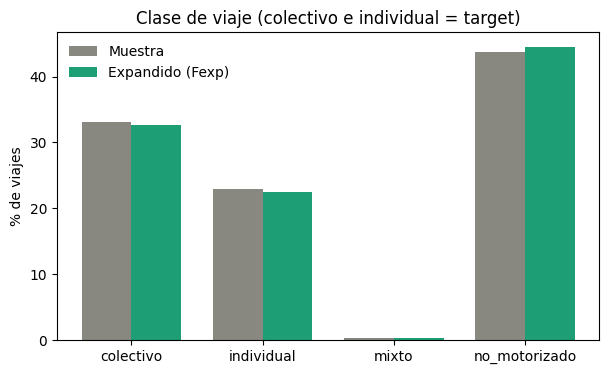

In [35]:
dist = distribucion_target(t)
display(dist)

d = dist.set_index("clase_viaje")
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(d)); w = .38
ax.bar(x - w / 2, d["pct_muestra"], w, label="Muestra", color="#888780")
ax.bar(x + w / 2, d["pct_expandido"], w, label="Expandido (Fexp)", color="#1D9E75")
ax.set_xticks(x, d.index); ax.set_ylabel("% de viajes"); ax.legend(frameon=False)
ax.set_title("Clase de viaje (colectivo e individual = target)")

### 4.2 Integridad referencial
Llaves primarias duplicadas y llaves foráneas sin correspondencia en la tabla destino.

In [36]:
integ = integridad(t)
integ

,tabla,chequeo,n_registros
0,dim_departamento,PK id_departamento duplicada,0
1,dim_municipio,PK id_municipio duplicada,0
2,dim_municipio,FK id_departamento sin match en dim_departamento,0
3,dim_localidad,PK id_localidad duplicada,0
4,dim_localidad,FK id_municipio sin match en dim_municipio,0
5,dim_zona,PK id_zat duplicada,0
6,dim_zona,FK id_localidad sin match en dim_localidad,0
7,dim_zona,FK id_municipio sin match en dim_municipio,0
8,dim_hogar,PK id_hogar duplicada,0
9,dim_hogar,FK id_zat sin match en dim_zona,0


### 4.3 Nulos en el dataset de modelado
La columna `tipo_probable` indica si el nulo se explica por un salto del cuestionario (nulo estructural) o si hay que revisarlo. Los estructurales conviene tratarlos como una categoría propia ("no aplica") y no imputarlos con la media.

,tabla,variable,n_nulos,pct_nulos,tipo_probable
17,dataset_modelo,madre_cabeza_familia,30271,53.94,Solo se pregunta a mujeres
37,dataset_modelo,hogar_modelo_mas_reciente,28174,50.20,Hogar sin vehículo con placa
40,dataset_modelo,localidad_destino,16435,29.28,ZAT fuera de Bogotá o sin hogares
39,dataset_modelo,localidad_origen,16301,29.05,ZAT fuera de Bogotá o sin hogares
31,dataset_modelo,ingreso_rango,11649,20.76,Incluye NS/NR recodificado
26,dataset_modelo,estrato,10638,18.96,Solo hogares de Bogotá (municipios no tienen e...
20,dataset_modelo,licencia_moto,3848,6.86,No se pregunta a menores
19,dataset_modelo,licencia_carro,3848,6.86,No se pregunta a menores
4,dataset_modelo,id_motivo,9,0.02,Incluye NS/NR recodificado


Text(0.5, 1.0, 'Nulos en el dataset de modelado')

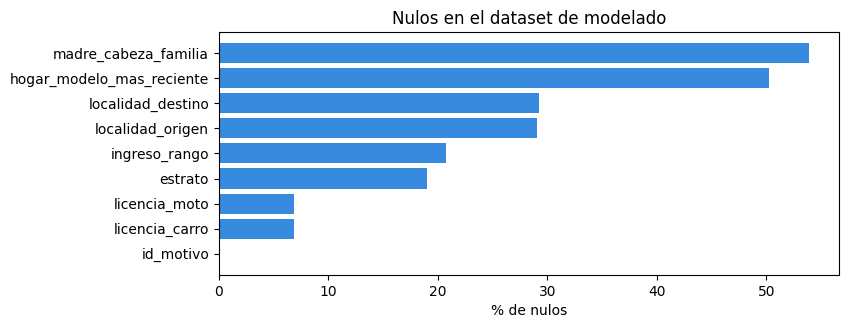

In [37]:
nulos_ds = tabla_nulos(ds, "dataset_modelo")
display(nulos_ds)

top = nulos_ds.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, max(3, .35 * len(top))))
ax.barh(top["variable"], top["pct_nulos"], color="#378ADD")
ax.set_xlabel("% de nulos"); ax.set_title("Nulos en el dataset de modelado")

### 4.4 Nulos en todas las tablas del modelo

In [38]:
nulos = pd.concat([tabla_nulos(df, n) for n, df in t.items()], ignore_index=True)
nulos

,tabla,variable,n_nulos,pct_nulos,tipo_probable
0,dim_zona,upz,582,50.09,ZAT sin hogares en la muestra
1,dim_zona,id_localidad,582,50.09,ZAT fuera de Bogotá o sin hogares
2,dim_zona,utam,465,40.02,ZAT sin hogares en la muestra
3,dim_zona,id_municipio,3,0.26,Revisar
4,dim_hogar,estrato,5249,23.07,Solo hogares de Bogotá (municipios no tienen e...
5,dim_hogar,ingreso_rango,4806,21.12,Incluye NS/NR recodificado
6,dim_vehiculo,id_municipio_matricula,4165,35.18,Revisar
7,dim_vehiculo,modelo_anio,1210,10.22,Revisar
8,dim_persona,madre_cabeza_familia,37019,54.80,Solo se pregunta a mujeres
9,dim_persona,modo_2019,19017,28.15,Solo responde módulo E


### 4.5 Atípicos
Criterio IQR (fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR) y z robusto con la mediana y el MAD (|z| > 3,5). En conteos concentrados en 0 o 1 el IQR vale 0 y el criterio no aplica; la columna `nota` lo indica.

In [39]:
atip = pd.concat([tabla_atipicos(ds, "dataset_modelo", CONTINUAS["dataset_modelo"]),
                  tabla_atipicos(t["fact_etapa"], "fact_etapa", CONTINUAS["fact_etapa"])], ignore_index=True)
atip

,tabla,variable,n,min,q1,mediana,q3,max,lim_inf_iqr,lim_sup_iqr,n_atipicos_iqr,pct_atipicos_iqr,n_atipicos_z_robusto>3.5,nota
0,dataset_modelo,edad,56122,5.000000,25.000000,38.000000,54.000000,96.000000,-18.500000,97.500000,0,0.00,0,
1,dataset_modelo,duracion_min,56122,3.000000,31.000000,60.000000,90.000000,857.000000,-57.500000,178.500000,1493,2.66,263,
2,dataset_modelo,n_personas,56122,1.000000,2.000000,3.000000,4.000000,11.000000,-1.000000,7.000000,718,1.28,341,
3,dataset_modelo,n_personas_5mas,56122,1.000000,2.000000,3.000000,4.000000,11.000000,-1.000000,7.000000,528,0.94,232,
4,dataset_modelo,n_hogares_vivienda,56122,1.000000,1.000000,1.000000,1.000000,5.000000,1.000000,1.000000,10747,19.15,0,"IQR = 0: variable discreta concentrada, el cri..."
5,dataset_modelo,n_autos,56122,0.000000,0.000000,0.000000,1.000000,5.000000,-1.500000,2.500000,498,0.89,0,
6,dataset_modelo,n_motos,56122,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,13019,23.20,0,"IQR = 0: variable discreta concentrada, el cri..."
7,dataset_modelo,n_bicicletas,56122,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,10783,19.21,0,"IQR = 0: variable discreta concentrada, el cri..."
8,dataset_modelo,n_vehiculos_placa,56122,0.000000,0.000000,1.000000,1.000000,7.000000,-1.500000,2.500000,1657,2.95,14,
9,dataset_modelo,hogar_modelo_mas_reciente,27948,1950.000000,2013.000000,2018.000000,2021.000000,2024.000000,2001.000000,2033.000000,1597,5.71,1826,


Text(0.5, 0.98, 'Variables continuas por clase (puntos = atípicos IQR)')

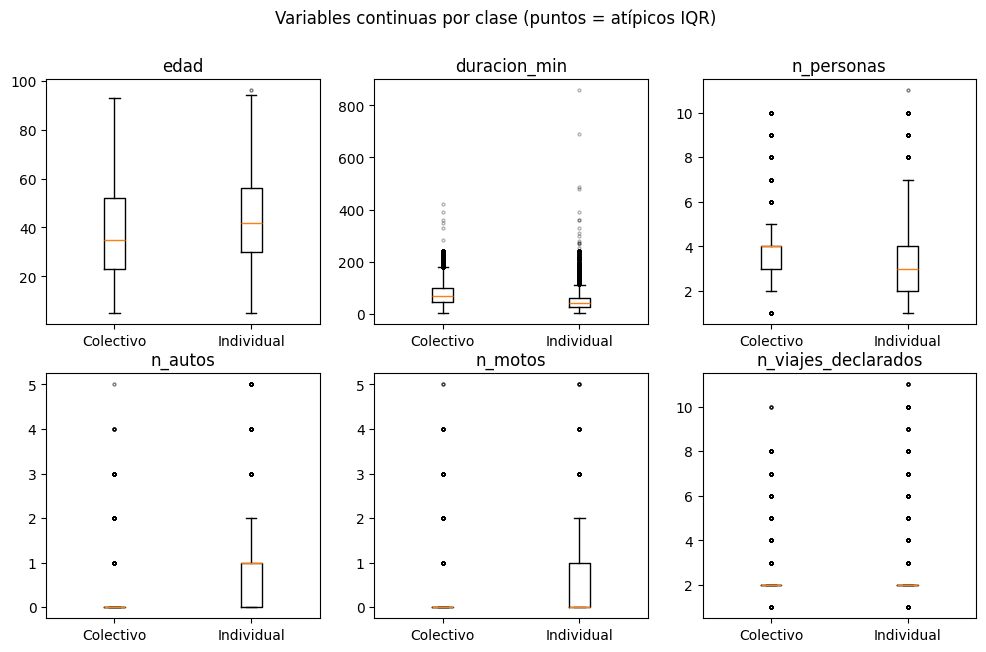

In [40]:
vars_box = ["edad", "duracion_min", "n_personas", "n_autos", "n_motos", "n_viajes_declarados"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, v in zip(axes.flat, vars_box):
    datos_box = [ds.loc[ds["target_individual"] == k, v].dropna() for k in (0, 1)]
    ax.boxplot(datos_box, tick_labels=["Colectivo", "Individual"], flierprops={"markersize": 2, "alpha": .3})
    ax.set_title(v)
fig.suptitle("Variables continuas por clase (puntos = atípicos IQR)")

### 4.6 Reglas de dominio
Valores imposibles o inconsistentes según el sentido de cada variable (no solo según su distribución).

In [41]:
reglas = reglas_dominio(t, ds)
reglas

,tabla,regla,n_registros
0,dim_persona,Edad > 100 años,8
1,dim_persona,Viajes declarados (d6a) ≠ viajes registrados,0
2,dim_hogar,Más de 15 personas en el hogar,0
3,dim_hogar,Personas ≥5 años > total de personas,0
4,dim_vehiculo,Modelo del vehículo < 1960 o > 2024,13
5,fact_viaje,Duración = 0 min (misma hora de salida y llegada),0
6,fact_viaje,val_d28 contradice las horas (cruce de mediano...,582
7,fact_viaje,Duración > 240 min,28
8,fact_viaje,Sin hora de salida o de llegada,0
9,fact_viaje,Etapas declaradas (d12a) ≠ etapas registradas,0


## Conclusiones para la etapa de modelado

- **Target:** unos 56.100 viajes motorizados, aprox. 59 % colectivos y 41 % individuales (casi igual con el factor de expansión). El desbalance es moderado; no hace falta SMOTE, aunque se puede usar `class_weight`.
- **Nulos:** los del dataset son estructurales (estrato solo en Bogotá, madre cabeza de familia solo en mujeres, año del vehículo solo si el hogar tiene uno, ingreso con NS/NR, localidad fuera de Bogotá). Se recomienda codificarlos como categoría "no aplica".
- **Atípicos:** la duración tiene una cola larga (≈2,7 % sobre el límite IQR; algunos viajes > 4 h); conviene recortarla (*winsorizar*) o transformarla con logaritmo. Los pasajes > $20.000 en transporte colectivo y los años de vehículo imposibles son errores de digitación.
- **Fuga de información:** no usar espera, pasaje, parqueo, vehículo usado, apps durante el viaje ni conteos de etapas como predictores.
- **Usar `fexp`** como peso si se quieren conclusiones representativas de Bogotá.

# 5. Preprocesamiento de datos

En esta etapa se prepara el conjunto de datos para la clasificación entre transporte colectivo e individual motorizado, a partir de las tablas integradas de la Encuesta de Movilidad Bogotá 2023.

Se revisan los valores faltantes, registros duplicados, valores atípicos y la consistencia de las variables. Posteriormente, se definen las transformaciones necesarias para utilizar los datos en los modelos de clasificación.

El preprocesamiento se realizará evitando fugas de información entre los conjuntos de entrenamiento y prueba.

In [44]:
# 5.1 Verificación de inconsistencias

ds_limpio = ds.copy()

print("Registros iniciales:", len(ds_limpio))

print("\nIdentificadores de viaje duplicados:")
print(ds_limpio["id_viaje"].duplicated().sum())

print("\nEdades fuera del rango de revisión (0 a 110):")
print((~ds_limpio["edad"].between(0, 110)).sum())

print("\nDuraciones negativas:")
print((ds_limpio["duracion_min"] < 0).sum())

print("\nDuraciones iguales a cero:")
print((ds_limpio["duracion_min"] == 0).sum())

print("\nDistribución del target:")
print(ds_limpio["target_individual"].value_counts(dropna=False))

Registros iniciales: 56122

Identificadores de viaje duplicados:
0

Edades fuera del rango de revisión (0 a 110):
0

Duraciones negativas:
0

Duraciones iguales a cero:
0

Distribución del target:
target_individual
0.0    33222
1.0    22900
Name: count, dtype: int64



### 5.2 Selección de características

Se definen dos conjuntos de predictores: uno socioeconómico (8 variables) y otro ampliado con características del desplazamiento (13 variables), para comparar su desempeño predictivo.



In [45]:
# 5.2 Selección de características para clasificación

variables_socioeconomicas = [
    "edad",
    "sexo",
    "ingreso_rango",
    "estrato",
    "nivel_educativo",
    "actividad_principal",
    "n_autos",
    "n_motos"
]

variables_desplazamiento = [
    "id_motivo",
    "franja_salida",
    "intermunicipal",
    "misma_zat",
    "misma_localidad"
]

variables_ampliadas = (
    variables_socioeconomicas + variables_desplazamiento
)

# Dos conjuntos para comparar el aporte de los viajes
X_socio = ds_limpio[variables_socioeconomicas].copy()
X_ampliado = ds_limpio[variables_ampliadas].copy()

# Variable objetivo
y = ds_limpio["target_individual"].astype(int)

print("Dataset socioeconómico:", X_socio.shape)
print("Dataset ampliado:", X_ampliado.shape)
print("Variable objetivo:", y.shape)

print("\nValores faltantes del conjunto ampliado:")
print(X_ampliado.isna().sum()[X_ampliado.isna().sum() > 0])

Dataset socioeconómico: (56122, 8)
Dataset ampliado: (56122, 13)
Variable objetivo: (56122,)

Valores faltantes del conjunto ampliado:
ingreso_rango    11649
estrato          10638
id_motivo            9
dtype: int64



### 5.3 Reducción de dimensionalidad

Se seleccionaron 13 variables predictoras de las 45 columnas disponibles, excluyendo identificadores y campos no utilizados en el modelo. No se aplicó PCA para conservar la interpretabilidad de las variables.



### 5.4 Transformación y codificación

Se configuran pipelines de imputación y codificación categórica. Las variables numéricas se estandarizan para regresión logística, mientras que Random Forest conserva su escala original. Los transformadores se ajustarán únicamente con los datos de entrenamiento.


In [46]:
# 5.4 Preparación de transformaciones para modelado

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

variables_numericas = [
    "edad",
    "n_autos",
    "n_motos"
]

variables_categoricas = [
    "sexo",
    "ingreso_rango",
    "estrato",
    "nivel_educativo",
    "actividad_principal",
    "id_motivo",
    "franja_salida",
    "intermunicipal",
    "misma_zat",
    "misma_localidad"
]

def crear_preprocesador(columnas, escalar=True):
    numericas = [c for c in variables_numericas if c in columnas]
    categoricas = [c for c in variables_categoricas if c in columnas]

    pasos_numericos = [
        ("imputar", SimpleImputer(strategy="median"))
    ]

    if escalar:
        pasos_numericos.append(
            ("escalar", StandardScaler())
        )

    transformador_numerico = Pipeline(
        steps=pasos_numericos
    )

    transformador_categorico = Pipeline(
        steps=[
            (
                "imputar",
                SimpleImputer(
                    strategy="constant",
                    fill_value=-1
                )
            ),
            (
                "codificar",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numericas", transformador_numerico, numericas),
            ("categoricas", transformador_categorico, categoricas)
        ]
    )

# Preparar los transformadores, sin ajustarlos todavía
prep_socio_logistica = crear_preprocesador(
    X_socio.columns, escalar=True
)

prep_ampliado_logistica = crear_preprocesador(
    X_ampliado.columns, escalar=True
)

prep_socio_rf = crear_preprocesador(
    X_socio.columns, escalar=False
)

prep_ampliado_rf = crear_preprocesador(
    X_ampliado.columns, escalar=False
)

print("Transformadores configurados correctamente.")
print("Regresión logística: escalamiento habilitado.")
print("Random Forest: sin escalamiento.")
print("Todavía no se ajustaron con los datos.")

Transformadores configurados correctamente.
Regresión logística: escalamiento habilitado.
Random Forest: sin escalamiento.
Todavía no se ajustaron con los datos.



### 5.4 Validación del preprocesamiento

Se comprueba el funcionamiento de las transformaciones mediante una división provisional 80/20. El preprocesador se ajusta con entrenamiento y se aplica a prueba sin reajustarlo.


In [51]:
# 5.4 Validación del preprocesamiento

from sklearn.model_selection import train_test_split

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_ampliado,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Ajustar SOLO con los datos de entrenamiento
X_train_transformado = prep_ampliado_logistica.fit_transform(
    X_train
)

# Aplicar a prueba sin volver a ajustar
X_test_transformado = prep_ampliado_logistica.transform(
    X_test
)



print("\nEntrenamiento transformado:", X_train_transformado.shape)
print("Prueba transformada:", X_test_transformado.shape)

print("\nValores faltantes después de transformar:")
print("Entrenamiento:", X_train_transformado.shape[0] -
      X_train_transformado.shape[0])  # Solo verifica ejecución

print("\nPreprocesamiento aplicado correctamente.")

Entrenamiento original: (44897, 13)
Prueba original: (11225, 13)

Entrenamiento transformado: (44897, 90)
Prueba transformada: (11225, 90)

Valores faltantes después de transformar:
Entrenamiento: 0

Preprocesamiento aplicado correctamente.


In [52]:
# 5.4 Verificación final de las transformaciones
import numpy as np
from scipy import sparse

def contar_nulos(matriz):
    if sparse.issparse(matriz):
        return int(np.isnan(matriz.data).sum())
    return int(np.isnan(matriz).sum())

print("Nulos en entrenamiento:",
      contar_nulos(X_train_transformado))

print("Nulos en prueba:",
      contar_nulos(X_test_transformado))

print("Mismas columnas:",
      X_train_transformado.shape[1] == X_test_transformado.shape[1])

Nulos en entrenamiento: 0
Nulos en prueba: 0
Mismas columnas: True



### 6.1 Estadísticas descriptivas y visualizaciones

Se analiza la distribución de los tipos de transporte y su relación con las características socioeconómicas y los desplazamientos.


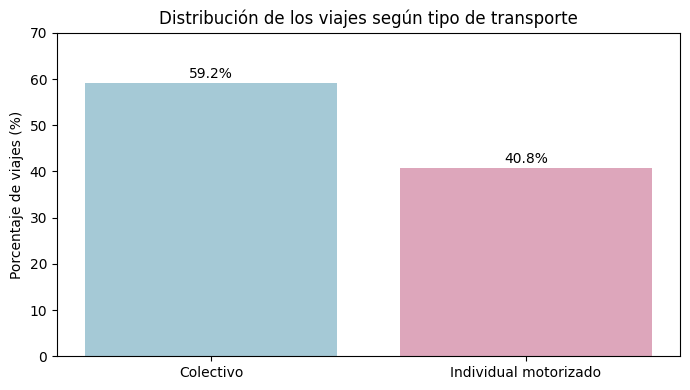

Viajes por categoría:
target_individual
0.0    33222
1.0    22900
Name: count, dtype: int64


In [53]:
# 6.1 Distribución de los tipos de transporte

import matplotlib.pyplot as plt

conteos = ds_limpio["target_individual"].value_counts().sort_index()
porcentajes = conteos / conteos.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    ["Colectivo", "Individual motorizado"],
    porcentajes.values,
    color=["#A5C9D6", "#DDA6BB"]
)

for barra, valor in zip(barras, porcentajes.values):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{valor:.1f}%",
        ha="center"
    )

ax.set_ylabel("Porcentaje de viajes (%)")
ax.set_title("Distribución de los viajes según tipo de transporte")
ax.set_ylim(0, 70)

plt.tight_layout()
plt.show()

print("Viajes por categoría:")
print(conteos)

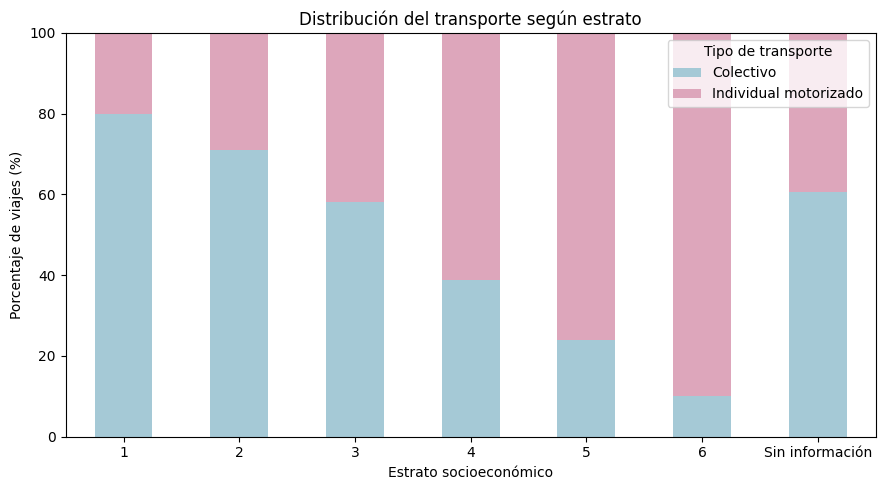

Porcentajes por estrato:


target_individual,Colectivo,Individual motorizado
estrato,,
1,80.0,20.0
2,71.0,29.0
3,58.0,42.0
4,38.7,61.3
5,23.9,76.1
6,10.0,90.0
Sin información,60.5,39.5



Número de viajes por estrato:
estrato
2                  13634
3                  13121
Sin información    10638
1                   8220
4                   5024
5                   3046
6                   2439
Name: count, dtype: int64


In [54]:
# 6.1 Elección del transporte según estrato

import pandas as pd
import matplotlib.pyplot as plt

# Crear copia para el análisis
eda_estrato = ds_limpio[
    ["estrato", "target_individual"]
].copy()

# Conservar los valores faltantes como categoría visible
eda_estrato["estrato"] = (
    eda_estrato["estrato"]
    .map(lambda x: str(int(x)) if pd.notna(x) else "Sin información")
)

# Calcular porcentajes dentro de cada estrato
tabla_estrato = pd.crosstab(
    eda_estrato["estrato"],
    eda_estrato["target_individual"],
    normalize="index"
) * 100

tabla_estrato = tabla_estrato.reindex(
    ["1", "2", "3", "4", "5", "6", "Sin información"]
)

tabla_estrato = tabla_estrato.rename(
    columns={0.0: "Colectivo", 1.0: "Individual motorizado"}
)

# Gráfica
ax = tabla_estrato.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#A5C9D6", "#DDA6BB"]
)

ax.set_title("Distribución del transporte según estrato")
ax.set_xlabel("Estrato socioeconómico")
ax.set_ylabel("Porcentaje de viajes (%)")
ax.legend(title="Tipo de transporte")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Porcentajes por estrato:")
display(tabla_estrato.round(1))

print("\nNúmero de viajes por estrato:")
print(eda_estrato["estrato"].value_counts())

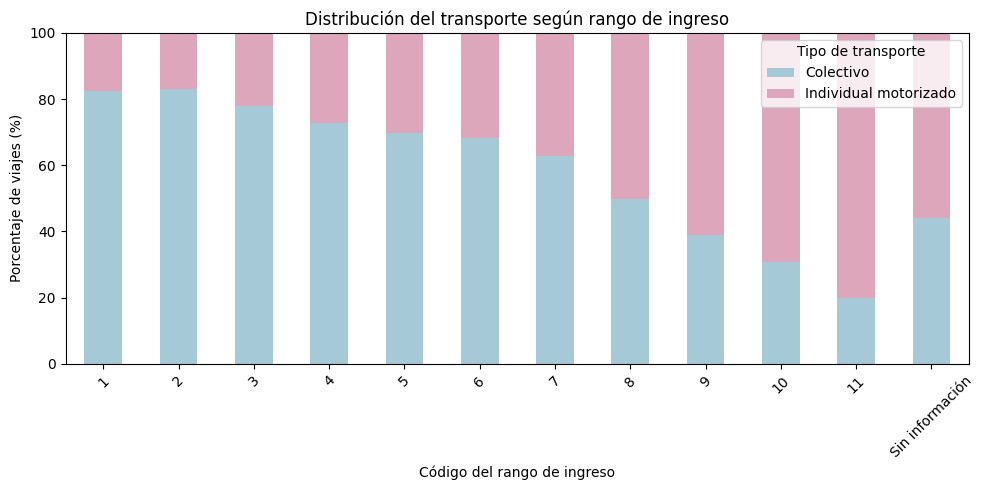

Porcentajes por rango de ingreso:


target_individual,Colectivo,Individual motorizado
ingreso_rango,,
1,82.3,17.7
2,82.9,17.1
3,77.7,22.3
4,72.8,27.2
5,69.7,30.3
6,68.3,31.7
7,62.8,37.2
8,49.8,50.2
9,38.9,61.1



Número de viajes por rango:
ingreso_rango
Sin información    11649
7                   6416
6                   6399
4                   6378
5                   6350
3                   5082
8                   4867
9                   3062
2                   1964
10                  1723
11                  1486
1                    746
Name: count, dtype: int64


In [55]:
# 6.1 Transporte individual según rango de ingreso

import pandas as pd
import matplotlib.pyplot as plt

eda_ingreso = ds_limpio[
    ["ingreso_rango", "target_individual"]
].copy()

eda_ingreso["ingreso_rango"] = (
    eda_ingreso["ingreso_rango"]
    .apply(
        lambda x: str(int(x))
        if pd.notna(x) else "Sin información"
    )
)

tabla_ingreso = pd.crosstab(
    eda_ingreso["ingreso_rango"],
    eda_ingreso["target_individual"],
    normalize="index"
) * 100

orden = sorted(
    [x for x in tabla_ingreso.index if x != "Sin información"],
    key=int
)

if "Sin información" in tabla_ingreso.index:
    orden.append("Sin información")

tabla_ingreso = tabla_ingreso.reindex(orden)

tabla_ingreso = tabla_ingreso.rename(
    columns={
        0.0: "Colectivo",
        1.0: "Individual motorizado"
    }
)

ax = tabla_ingreso.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["#A5C9D6", "#DDA6BB"]
)

ax.set_title("Distribución del transporte según rango de ingreso")
ax.set_xlabel("Código del rango de ingreso")
ax.set_ylabel("Porcentaje de viajes (%)")
ax.set_ylim(0, 100)
ax.legend(title="Tipo de transporte")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Porcentajes por rango de ingreso:")
display(tabla_ingreso.round(1))

print("\nNúmero de viajes por rango:")
print(eda_ingreso["ingreso_rango"].value_counts())

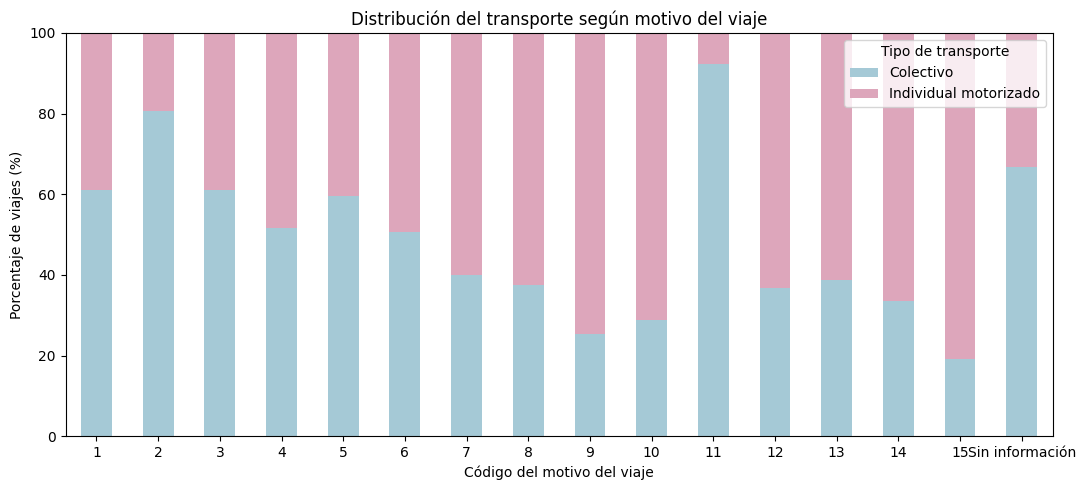

Porcentajes por motivo:


target_individual,Colectivo,Individual motorizado
motivo,,
1,61.1,38.9
2,80.5,19.5
3,61.1,38.9
4,51.5,48.5
5,59.5,40.5
6,50.6,49.4
7,40.1,59.9
8,37.5,62.5
9,25.3,74.7



Cantidad de viajes por motivo:
motivo
5                  26719
1                  14783
2                   3869
3                   3004
6                   2927
14                  1422
8                   1210
4                    817
9                    580
7                    267
11                   155
10                   139
12                   125
13                    49
15                    47
Sin información        9
Name: count, dtype: int64


In [56]:
# 6.1 Distribución del transporte según motivo del viaje

import pandas as pd
import matplotlib.pyplot as plt

eda_motivo = ds_limpio[
    ["id_motivo", "target_individual"]
].copy()

eda_motivo["motivo"] = eda_motivo["id_motivo"].apply(
    lambda x: str(int(x)) if pd.notna(x) else "Sin información"
)

tabla_motivo = pd.crosstab(
    eda_motivo["motivo"],
    eda_motivo["target_individual"],
    normalize="index"
) * 100

orden = sorted(
    [x for x in tabla_motivo.index if x != "Sin información"],
    key=int
)

if "Sin información" in tabla_motivo.index:
    orden.append("Sin información")

tabla_motivo = tabla_motivo.reindex(orden)

tabla_motivo = tabla_motivo.rename(
    columns={
        0.0: "Colectivo",
        1.0: "Individual motorizado"
    }
)

fig, ax = plt.subplots(figsize=(11, 5))

tabla_motivo.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#A5C9D6", "#DDA6BB"]
)

ax.set_title("Distribución del transporte según motivo del viaje")
ax.set_xlabel("Código del motivo del viaje")
ax.set_ylabel("Porcentaje de viajes (%)")
ax.set_ylim(0, 100)
ax.legend(title="Tipo de transporte")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Porcentajes por motivo:")
display(tabla_motivo.round(1))

print("\nCantidad de viajes por motivo:")
print(eda_motivo["motivo"].value_counts())

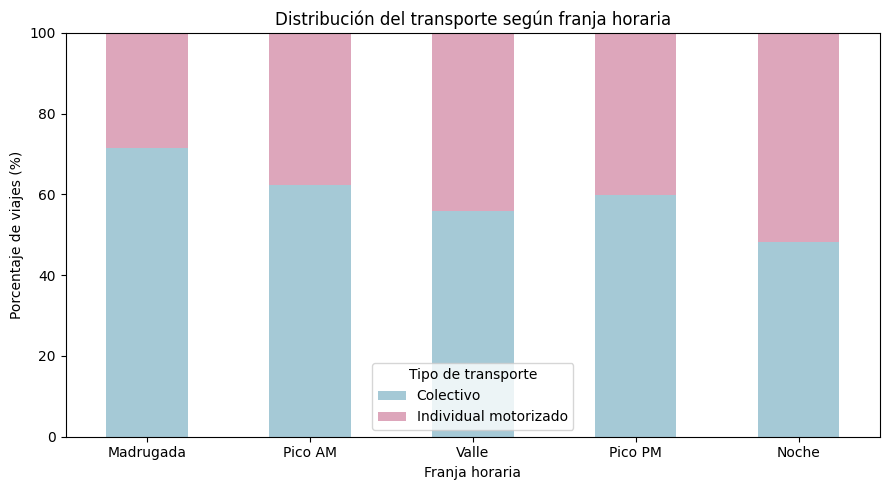

Porcentajes por franja horaria:


target_individual,Colectivo,Individual motorizado
franja_salida,,
Madrugada,71.4,28.6
Pico AM,62.4,37.6
Valle,56.0,44.0
Pico PM,60.0,40.0
Noche,48.2,51.8



Cantidad de viajes por franja:
franja_salida
Valle        20322
Pico AM      18635
Pico PM      12957
Noche         2359
Madrugada     1849
Name: count, dtype: int64


In [57]:
# 6.1 Distribución del transporte según franja horaria

import pandas as pd
import matplotlib.pyplot as plt

orden_franjas = [
    "Madrugada",
    "Pico AM",
    "Valle",
    "Pico PM",
    "Noche"
]

tabla_horario = pd.crosstab(
    ds_limpio["franja_salida"],
    ds_limpio["target_individual"],
    normalize="index"
) * 100

tabla_horario = tabla_horario.reindex(orden_franjas)

tabla_horario = tabla_horario.rename(
    columns={
        0.0: "Colectivo",
        1.0: "Individual motorizado"
    }
)

ax = tabla_horario.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#A5C9D6", "#DDA6BB"]
)

ax.set_title("Distribución del transporte según franja horaria")
ax.set_xlabel("Franja horaria")
ax.set_ylabel("Porcentaje de viajes (%)")
ax.set_ylim(0, 100)
ax.legend(title="Tipo de transporte")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Porcentajes por franja horaria:")
display(tabla_horario.round(1))

print("\nCantidad de viajes por franja:")
print(ds_limpio["franja_salida"].value_counts())


#### Distribución ponderada y sin ponderar

Se compara la proporción observada de viajes con la estimación obtenida al aplicar el factor de expansión (`fexp`) de la encuesta.


In [58]:
# 6.1 Comparación de distribución sin ponderar y ponderada

import numpy as np
import pandas as pd

eda_ponderado = ds_limpio[
    ["target_individual", "fexp"]
].copy()

eda_ponderado["fexp"] = pd.to_numeric(
    eda_ponderado["fexp"], errors="coerce"
)

# Validar factores de expansión
validos = (
    np.isfinite(eda_ponderado["fexp"])
    & (eda_ponderado["fexp"] > 0)
)

print("Viajes totales:", len(eda_ponderado))
print("Factores válidos:", validos.sum())
print("Factores inválidos:", (~validos).sum())

# Porcentaje sin ponderar
sin_ponderar = (
    eda_ponderado["target_individual"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Porcentaje ponderado
datos_validos = eda_ponderado.loc[validos]

suma_pesos = datos_validos.groupby(
    "target_individual"
)["fexp"].sum()

ponderado = suma_pesos / suma_pesos.sum() * 100

comparacion = pd.DataFrame({
    "Sin ponderar (%)": sin_ponderar,
    "Ponderado (%)": ponderado
})

comparacion.index = [
    "Colectivo",
    "Individual motorizado"
]

display(comparacion.round(2))

Viajes totales: 56122
Factores válidos: 56122
Factores inválidos: 0


,Sin ponderar (%),Ponderado (%)
Colectivo,59.2,59.26
Individual motorizado,40.8,40.74



### 6.2 Formulación y contraste de hipótesis

Se evalúa la asociación entre el tipo de transporte y cuatro variables mediante chi-cuadrado. La intensidad de las relaciones se mide con V de Cramér. Las pruebas tienen carácter exploratorio.


In [59]:
# 6.2 Pruebas de asociación entre variables y tipo de transporte

from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np

variables_hipotesis = [
    "estrato",
    "ingreso_rango",
    "id_motivo",
    "franja_salida"
]

resultados = []

for variable in variables_hipotesis:

    # Excluir faltantes únicamente para cada prueba
    muestra = ds_limpio[
        [variable, "target_individual"]
    ].dropna()

    tabla = pd.crosstab(
        muestra[variable],
        muestra["target_individual"]
    )

    chi2, p, gl, esperados = chi2_contingency(tabla)

    # V de Cramér: tamaño de la asociación
    n = tabla.to_numpy().sum()
    v_cramer = np.sqrt(
        chi2 / (n * min(tabla.shape[0]-1, tabla.shape[1]-1))
    )

    resultados.append({
        "Variable": variable,
        "Observaciones": n,
        "Chi-cuadrado": round(chi2, 2),
        "p-valor": p,
        "V de Cramér": round(v_cramer, 3)
    })

tabla_hipotesis = pd.DataFrame(resultados)

display(tabla_hipotesis)

,Variable,Observaciones,Chi-cuadrado,p-valor,V de Cramér
0,estrato,45484,7128.44,0.000000e+00,0.396
1,ingreso_rango,44473,4474.25,0.000000e+00,0.317
2,id_motivo,56113,1992.97,0.000000e+00,0.188
3,franja_salida,56122,399.63,3.349662e-85,0.084



### 6.3 Patrones y hallazgos

- **Distribución:** 59,26 % de los viajes son colectivos y 40,74 % individuales motorizados (ponderados).
- **Estrato e ingreso:** se observa una mayor proporción de transporte individual en las categorías socioeconómicas más altas.
- **Motivo y horario:** presentan diferencias entre tipos de transporte, especialmente durante la noche.
- **Asociaciones exploratorias:** estrato (V = 0,396), ingreso (V = 0,317), motivo (V = 0,188) y horario (V = 0,084).

Los resultados muestran asociaciones, no causalidad. Las pruebas de asociación y los análisis por subgrupo son exploratorios y no están ajustados por el diseño muestral.
